In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, association_rules
import warnings
warnings.filterwarnings('ignore')

#Importamos el archivo CSV dataset desde GItHub
url = "https://raw.githubusercontent.com/ianmadariaga07/DataMining_Project_1908/main/online_shoppers_clean.csv"
df = pd.read_csv(url)

#Imprimimos
print(f"Dimensiones del dataset: {df.shape[0]} filas x {df.shape[1]} columnas")
print(f"Valores nulos totales: {df.isna().sum().sum()}")
print(f"Duplicados totales: {df.duplicated().sum()}")

#Imprime y cuenta cuantos True y False hay en la columan Revenue
print("\nDistribución de Revenue (%):")
print((df['Revenue'].value_counts(normalize=True) * 100).round(2))
df.head(3)



Dimensiones del dataset: 12205 filas x 21 columnas
Valores nulos totales: 0
Duplicados totales: 0

Distribución de Revenue (%):
Revenue
False    84.37
True     15.63
Name: proportion, dtype: float64


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue,Total_Pages,Visited_PageValues,Visited_Admin
0,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,...,1,1,1,1,Returning_Visitor,False,False,1,0,0
1,0,0.0,0,0.0,2,64.0,0.0,0.1,0.0,0.0,...,2,2,1,2,Returning_Visitor,False,False,2,0,0
2,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,...,4,1,9,3,Returning_Visitor,False,False,1,0,0


## Nota 1:
Se importaron las librerías necesarias.
El conjunto cuenta con exactamente 12,205 sesiones y 21 variables, presentando 0 valores nulos y 0 registros duplicados tras la limpieza base del equipo.
El 84.37% de las sesiones terminan sin compra (False) frente al 15.63% que sí concretan una compra (True). Este desbalanceo es clave para el diseño de Apriori.


##Discretización y Binarización

In [ ]:
# Creamos un DataFrame vacío de tipo booleano para nuestra matriz transaccional
df_trans = pd.DataFrame(index=df.index)

# Variable Objetivo: Compra vs No Compra
df_trans['Compro_True'] = (df['Revenue'] == True)
df_trans['NoCompro_False'] = (df['Revenue'] == False)

# Variable de negocio clave: ¿Visitó página con valor comercial (PageValues > 0)?
# CREAR ITEMS DE PAGINAS DE VALOR Y ADMINISTRATIVAS DESDE VARIABLES NUEVAS
df_trans['PaginaValor_Si'] = (df['Visited_PageValues'] == 1)
df_trans['PaginaValor_Cero'] = (df['Visited_PageValues'] == 0)
df_trans['VisitoAdmin_Si'] = (df['Visited_Admin'] == 1)
df_trans['VisitoAdmin_No'] = (df['Visited_Admin'] == 0)

# Cantidad de páginas de producto visitadas
df_trans['Productos_Pocos(0-5)'] = (df['ProductRelated'] <= 5)
df_trans['Productos_Medio(6-25)'] = (df['ProductRelated'] > 5) & (df['ProductRelated'] <= 25)
df_trans['Productos_Muchos(>25)'] = (df['ProductRelated'] > 25)

# Tiempo invertido en páginas de producto (en segundos)
df_trans['TiempoProd_Corto(<1min)'] = (df['ProductRelated_Duration'] <= 60)
df_trans['TiempoProd_Medio(1-10min)'] = (df['ProductRelated_Duration'] > 60) & (df['ProductRelated_Duration'] <= 600)
df_trans['TiempoProd_Largo(>10min)'] = (df['ProductRelated_Duration'] > 600)

# Tasa de rebote y Salida
df_trans['Rebote_Cero'] = (df['BounceRates'] == 0)
df_trans['Rebote_Alto(>0.05)'] = (df['BounceRates'] > 0.05)
df_trans['Salida_Baja(<0.02)'] = (df['ExitRates'] < 0.02)

# Tipo de Visitante y Temporalidad
df_trans['Visitante_Recurrente'] = (df['VisitorType'] == 'Returning_Visitor')
df_trans['Visitante_Nuevo'] = (df['VisitorType'] == 'New_Visitor')
df_trans['FinDeSemana_Si'] = (df['Weekend'] == True)
df_trans['EntreSemana'] = (df['Weekend'] == False)
df_trans['FechaEspecial_Si'] = (df['SpecialDay'] > 0)

# Meses más relevantes
meses_dummies = pd.get_dummies(df['Month'], prefix='Mes').astype(bool)
df_trans = pd.concat([df_trans, meses_dummies], axis=1)

# Principales fuentes de tráfico
for t in [1, 2, 3, 4]:
    df_trans[f'Trafico_Tipo_{t}'] = (df['TrafficType'] == t)

##Nota 2:
Se conectaron directamente las banderas booleanas creadas en el preprocesamiento (Visited_PageValues y Visited_Admin) para generar los ítems PaginaValor_Si/Cero y VisitoAdmin_Si/No.
Se segmentaron las páginas de producto vistas, la duración en productos, métricas de abandono, perfil del usuario, estacionalidad por mes y las 4 principales fuentes de tráfico .

In [ ]:
df_trans = df_trans.astype(bool)

print(f"Matriz transaccional lista: {df_trans.shape[0]} sesiones x {df_trans.shape[1]} ítems binarios")
df_trans.head(3)

Matriz transaccional lista: 12205 sesiones x 34 ítems binarios


,Compro_True,NoCompro_False,PaginaValor_Si,PaginaValor_Cero,VisitoAdmin_Si,VisitoAdmin_No,Productos_Pocos(0-5),Productos_Medio(6-25),Productos_Muchos(>25),TiempoProd_Corto(<1min),...,Mes_June,Mes_Mar,Mes_May,Mes_Nov,Mes_Oct,Mes_Sep,Trafico_Tipo_1,Trafico_Tipo_2,Trafico_Tipo_3,Trafico_Tipo_4
0,False,True,False,True,False,True,True,False,False,True,...,False,False,False,False,False,False,True,False,False,False
1,False,True,False,True,False,True,True,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,False,True,False,True,False,True,True,False,False,True,...,False,False,False,False,False,False,False,False,True,False


##Nota 3:
Se aseguró que las 34 columnas resultantes tengan tipo estricto bool, obteniendo una matriz transaccional final de 12,205 sesiones × 34 ítems binarios.

Los ítems más comunes en toda la tienda son Visitante_Recurrente (85.46%, 10,431 sesiones), NoCompro_False (84.37%, 10,297 sesiones), PaginaValor_Cero (77.63%, 9,475 sesiones) y EntreSemana (76.58%, 9,346 sesiones). En comportamiento de navegación destaca que el 50.44% de las sesiones tienen una duración larga en productos (>10 min) y el 45.21% registran cero rebote (Rebote_Cero).

##Frecuencia individual de los ítems


In [ ]:
# Calculamos el soporte individual
soporte_individual = df_trans.mean(axis=0).sort_values(ascending=False)

# Tabla resumen de soporte (%)
df_soporte = pd.DataFrame({
    'Item': soporte_individual.index,
    'Sesiones': df_trans.sum()[soporte_individual.index].values,
    'Soporte (%)': (soporte_individual.values * 100).round(2)
})
display(df_soporte.head(15))

,Item,Sesiones,Soporte (%)
0,Visitante_Recurrente,10431,85.46
1,NoCompro_False,10297,84.37
2,PaginaValor_Cero,9475,77.63
3,EntreSemana,9346,76.58
4,VisitoAdmin_Si,6562,53.76
5,TiempoProd_Largo(>10min),6156,50.44
6,VisitoAdmin_No,5643,46.24
7,Rebote_Cero,5518,45.21
8,Productos_Medio(6-25),5302,43.44
9,Salida_Baja(<0.02),4675,38.30


##Nota 4:
La gráfica de barras permite comparar el soporte individual de cada característica frente a la línea roja de corte en 3% (equivalente a ~366 sesiones).

Elegir un soporte demasiado alto (ej. >15%) eliminaría por completo las transacciones exitosas (Compro_True tiene un soporte máximo individual del 15.63%, y sus combinaciones con otras variables son aún menores). Por el contrario, un umbral muy cercano a 0% generaría decenas de miles de reglas triviales sin relevancia estadística.

Fijar el corte en 3% garantiza conservar los ítems de conversión (Compro_True, PaginaValor_Si), los meses pico (Mes_May con 27.28%, Mes_Nov con 24.43%) y las fuentes de tráfico relevantes, filtrando combinaciones esporádicas sin peso comercial.

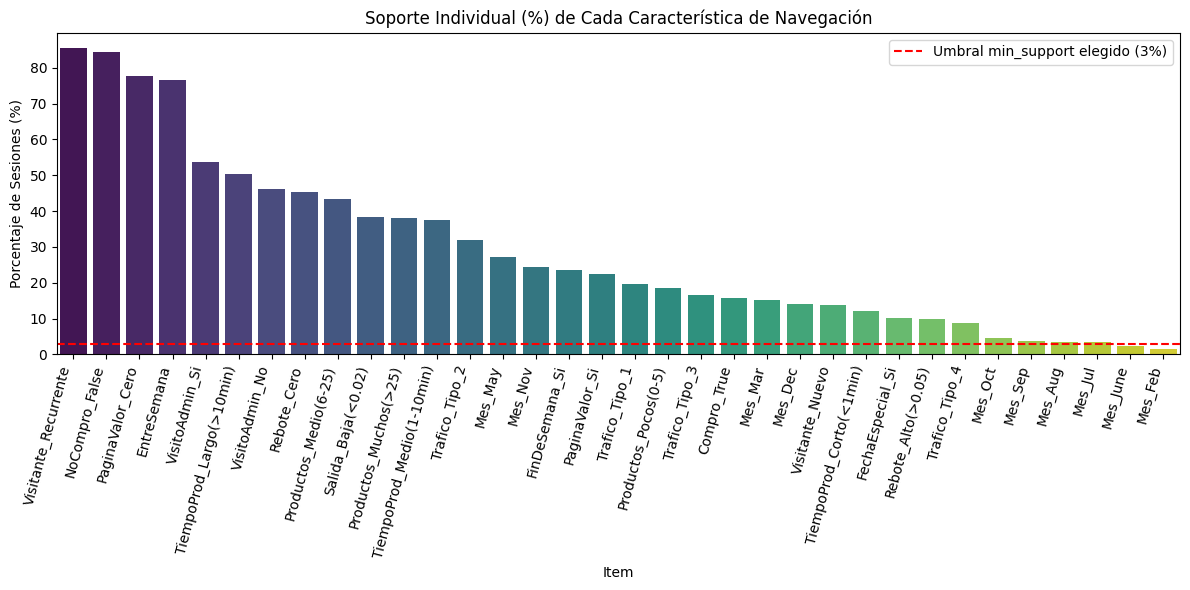

In [ ]:
# Gráfica de barras
plt.figure(figsize=(12, 6))
sns.barplot(x='Item', y='Soporte (%)', data=df_soporte, palette='viridis')
plt.axhline(3, color='red', linestyle='--', label='Umbral min_support elegido (3%)')
plt.xticks(rotation=75, ha='right')
plt.title('Soporte Individual (%) de Cada Característica de Navegación')
plt.ylabel('Porcentaje de Sesiones (%)')
plt.legend()
plt.tight_layout()
plt.show()

##Nota 5:
Se ejecutó el algoritmo Apriori sobre la matriz transaccional de 12,205 sesiones × 34 ítems, fijando min_support = 0.03 (3%) y limitando la longitud máxima a max_len = 4 para evitar combinaciones excesivamente complejas y redundantes.

Se identificaron 3,133 conjuntos frecuentes (de entre 1 y 4 ítems) que cumplen con aparecer en al menos ~366 sesiones.

Los pares dominantes en toda la tienda son (PaginaValor_Cero, NoCompro_False) con 74.86% de soporte y (NoCompro_False, Visitante_Recurrente) con 73.65%. Esto confirma numéricamente el patrón detectado en el EDA: la gran mayoría de los usuarios recurrentes navegan de forma exploratoria ("vitrineo") sin visitar páginas con valor comercial ni concretar compra.

##Algoritmo Apriori: Identificar los ítems frecuentes

In [ ]:
# Aplicamos Apriori con soporte mínimo del 3% (0.03 -> ~370 sesiones)
min_soporte = 0.03
itemsets = apriori(df_trans, min_support=min_soporte, use_colnames=True, max_len=4)

# Agregamos columna con el número de ítems en cada conjunto (k-itemset)
itemsets['longitud'] = itemsets['itemsets'].apply(lambda x: len(x))

print(f"Soporte mínimo aplicado: {min_soporte:.1%} (~{int(min_soporte * len(df_trans))} sesiones)")
print(f"Total de itemsets frecuentes encontrados: {len(itemsets)}")
print("\nTop 10 itemsets más frecuentes:")
display(itemsets.sort_values(by='support', ascending=False).head(10))

Soporte mínimo aplicado: 3.0% (~366 sesiones)
Total de itemsets frecuentes encontrados: 3133

Top 10 itemsets más frecuentes:


,support,itemsets,longitud
15,0.854650,(Visitante_Recurrente),1
1,0.843671,(NoCompro_False),1
3,0.776321,(PaginaValor_Cero),1
18,0.765752,(EntreSemana),1
49,0.746006,"(PaginaValor_Cero, NoCompro_False)",2
61,0.734207,"(Visitante_Recurrente, NoCompro_False)",2
102,0.663499,"(Visitante_Recurrente, PaginaValor_Cero)",2
269,0.660221,"(EntreSemana, Visitante_Recurrente)",2
64,0.650307,"(EntreSemana, NoCompro_False)",2
388,0.640967,"(Visitante_Recurrente, PaginaValor_Cero, NoCompro_False)",3


##Nota 6:
Se aplicó association_rules() con un umbral exploratorio de min_threshold = 0.25 (25%). Dado que la tasa base de compra (Compro_True) es de apenas 15.63%, fijar la confianza mínima en 25% garantiza que cualquier regla hacia la compra supere en más de un 60% el promedio general del sitio ($\text{Lift} > 1.6$), evitando descartar patrones minoritarios valiosos.

Al ordenar las reglas generales por confianza, los primeros lugares alcanzan el 100% (1.00) apuntando hacia NoCompro_False.

Pese a tener 100% de confianza, estas reglas presentan un Lift de apenas ~1.18 (muy cercano a la independencia estadística de $\text{Lift} = 1.0$). Como el abandono ocurre de forma natural en el 84.37% de las sesiones, prácticamente cualquier condición frecuente arroja una confianza artificialmente alta hacia la no compra aportando poca ganancia informativa real frente al azar.

##Generar y filtrar reglas de asociacion

In [ ]:
# Generamos reglas con confianza mínima del 50% (0.50)
rules = association_rules(itemsets, metric="confidence", min_threshold=0.50)

# Formateamos antecedentes y consecuentes como texto limpio para leerlos fácil
rules['antecedents_str'] = rules['antecedents'].apply(lambda x: ', '.join(list(x)))
rules['consequents_str'] = rules['consequents'].apply(lambda x: ', '.join(list(x)))

print(f"Total de reglas generadas (confianza >= 50%): {len(rules)}")

print("\n--- TOP 5 REGLAS POR CONFIANZA ")
cols_mostrar = ['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']
display(rules.sort_values(by='confidence', ascending=False)[cols_mostrar].head(5))

Total de reglas generadas (confianza >= 50%): 8594

--- TOP 5 REGLAS POR CONFIANZA 


,antecedents_str,consequents_str,support,confidence,lift
357,"Mes_Mar, PaginaValor_Cero",NoCompro_False,0.128308,1.0,1.185297
360,"Mes_May, PaginaValor_Cero",NoCompro_False,0.211880,1.0,1.185297
351,"PaginaValor_Cero, FechaEspecial_Si",NoCompro_False,0.087997,1.0,1.185297
2552,"VisitoAdmin_No, PaginaValor_Cero, FechaEspecial_Si",NoCompro_False,0.064236,1.0,1.185297
4404,"Mes_May, Visitante_Recurrente, TiempoProd_Corto(<1min)",NoCompro_False,0.033265,1.0,1.185297


##Nota 7:
Se filtraron exclusivamente las reglas cuyo consecuente es Compro_True, identificando 79 reglas de alto impacto ordenadas por Lift y Confianza.

La regla más fuerte encontrada es {PaginaValor_Si, Rebote_Cero, Productos_Medio(6-25)} -> Compro_True, la cual presenta un soporte de 3.88% (~478 sesiones), una Confianza del 84.45% y un Lift de 5.46. Es decir, cuando se combinan estos tres comportamientos, la probabilidad de compra se multiplica por 5.46 veces respecto al promedio de la tienda.

Incluso una regla de solo dos antecedentes ({PaginaValor_Si, Rebote_Cero} -> Compro_True) abarca el 7.07% de todas las sesiones del sitio (~872 visitas) manteniendo una Confianza del 73.15% y un Lift de 4.73.


In [ ]:
print("\n--- TOP 5 REGLAS POR CONFIANZA ")
cols_mostrar = ['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']
display(rules.sort_values(by='confidence', ascending=False)[cols_mostrar].head(5))


--- TOP 5 REGLAS POR CONFIANZA 


,antecedents_str,consequents_str,support,confidence,lift
357,"Mes_Mar, PaginaValor_Cero",NoCompro_False,0.128308,1.0,1.185297
360,"Mes_May, PaginaValor_Cero",NoCompro_False,0.211880,1.0,1.185297
351,"PaginaValor_Cero, FechaEspecial_Si",NoCompro_False,0.087997,1.0,1.185297
2552,"VisitoAdmin_No, PaginaValor_Cero, FechaEspecial_Si",NoCompro_False,0.064236,1.0,1.185297
4404,"Mes_May, Visitante_Recurrente, TiempoProd_Corto(<1min)",NoCompro_False,0.033265,1.0,1.185297


##Nota 8:
Agrupa las reglas de alto soporte vinculadas a NoCompro_False, con bajo poder discriminante.

 Concentra las 79 reglas de Compro_True con soportes moderados (3% a 7%), pero con una asociación positiva robusta que se despega drásticamente de la línea de independencia ($\text{Lift} = 1$).

In [ ]:
# Generamos reglas exploratorias para no perder patrones de compra (base = 15.63%)
rules_all = association_rules(itemsets, metric="confidence", min_threshold=0.25)
rules_all['antecedents_str'] = rules_all['antecedents'].apply(lambda x: ', '.join(list(x)))
rules_all['consequents_str'] = rules_all['consequents'].apply(lambda x: ', '.join(list(x)))

# Filtramos reglas donde el consecuente sea exactamente 'Compro_True'
reglas_compra = rules_all[rules_all['consequents'] == frozenset({'Compro_True'})].copy()
reglas_compra = reglas_compra.sort_values(by=['lift', 'confidence'], ascending=False)

print(f"Reglas encontradas que predicen Compra (Compro_True): {len(reglas_compra)}")
print("\n--- TOP 10 REGLAS DE CONVERSION A COMPRA (Ordenadas por Lift) ---")
display(reglas_compra[cols_mostrar].head(10))

Reglas encontradas que predicen Compra (Compro_True): 110

--- TOP 10 REGLAS DE CONVERSION A COMPRA (Ordenadas por Lift) ---


,antecedents_str,consequents_str,support,confidence,lift
4009,"Productos_Medio(6-25), Salida_Baja(<0.02), PaginaValor_Si",Compro_True,0.031299,0.845133,5.406103
3998,"Productos_Medio(6-25), Rebote_Cero, PaginaValor_Si",Compro_True,0.039164,0.844523,5.402203
369,"VisitoAdmin_No, PaginaValor_Si",Compro_True,0.031790,0.793456,5.075540
381,"TiempoProd_Medio(1-10min), PaginaValor_Si",Compro_True,0.030643,0.774327,4.953177
4180,"Rebote_Cero, Trafico_Tipo_2, PaginaValor_Si",Compro_True,0.033429,0.740472,4.736614
4151,"Rebote_Cero, Salida_Baja(<0.02), PaginaValor_Si",Compro_True,0.056043,0.737069,4.714846
372,"Productos_Medio(6-25), PaginaValor_Si",Compro_True,0.051536,0.732247,4.684000
388,"Rebote_Cero, PaginaValor_Si",Compro_True,0.071446,0.731544,4.679502
4170,"EntreSemana, Rebote_Cero, PaginaValor_Si",Compro_True,0.052192,0.717342,4.588660
4023,"Productos_Medio(6-25), EntreSemana, PaginaValor_Si",Compro_True,0.037444,0.708527,4.532271


##Nota 9:
Tanto el ranking de barras horizontales como el grafo dirigido (NetworkX) demuestran que PaginaValor_Si, Rebote_Cero y una exploración moderada de productos (6 a 25 páginas) actúan como el núcleo central que impulsa las ventas.

Las reglas descubiertas representan patrones sólidos de co-ocurrencia histórica en las sesiones analizadas y no implican causalidad directa; sin embargo, sirven como guía accionable para priorizar campañas de retargeting sobre usuarios sin rebote que ya interactuaron con páginas de valor comercial.

##Graficas de Soporte vs Confianza

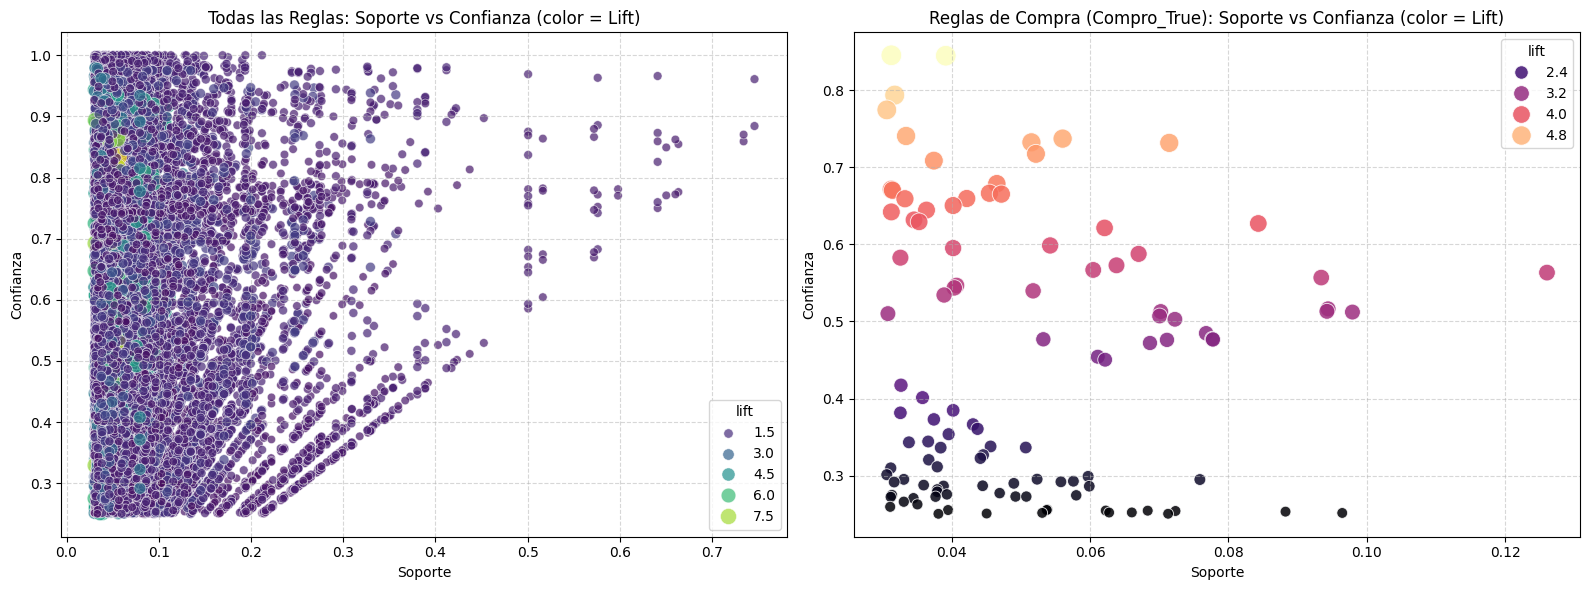

In [ ]:
pd.set_option('display.max_colwidth', None)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Grafica de todas las reglas
sns.scatterplot(
    data=rules_all, x='support', y='confidence', hue='lift',
    palette='viridis', size='lift', sizes=(30, 150), alpha=0.7, ax=axes[0]
)
axes[0].set_title('Todas las Reglas: Soporte vs Confianza (color = Lift)')
axes[0].set_xlabel('Soporte')
axes[0].set_ylabel('Confianza')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Gráfica de solo reglas que predicen Compra
sns.scatterplot(
    data=reglas_compra, x='support', y='confidence', hue='lift',
    palette='magma', size='lift', sizes=(60, 220), alpha=0.85, ax=axes[1]
)
axes[1].set_title('Reglas de Compra (Compro_True): Soporte vs Confianza (color = Lift)')
axes[1].set_xlabel('Soporte')
axes[1].set_ylabel('Confianza')
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

##Nota 10:
Aquí comparamos directamente qué combinaciones aumentan más la probabilidad de que el usuario compre (Compro_True).

Las 10 mejores reglas superan un Lift de 4.70 (casi 5 veces más probabilidad que el 15.63% base) y todas incluyen PaginaValor_Si. Si el usuario no toca una página con valor comercial, prácticamente no entra en las reglas fuertes de compra.

La regla más alta es {PaginaValor_Si, Rebote_Cero, Productos_Medio(6-25)} -> Compro_True con Lift = 5.46 y 84.45% de confianza. También aparecen sesiones con muchos productos (>25) y duración larga (>10 min) con Lift arriba de 5.10, así que tanto el que compra rápido como el que revisa mucho catálogo pasan por páginas de valor.


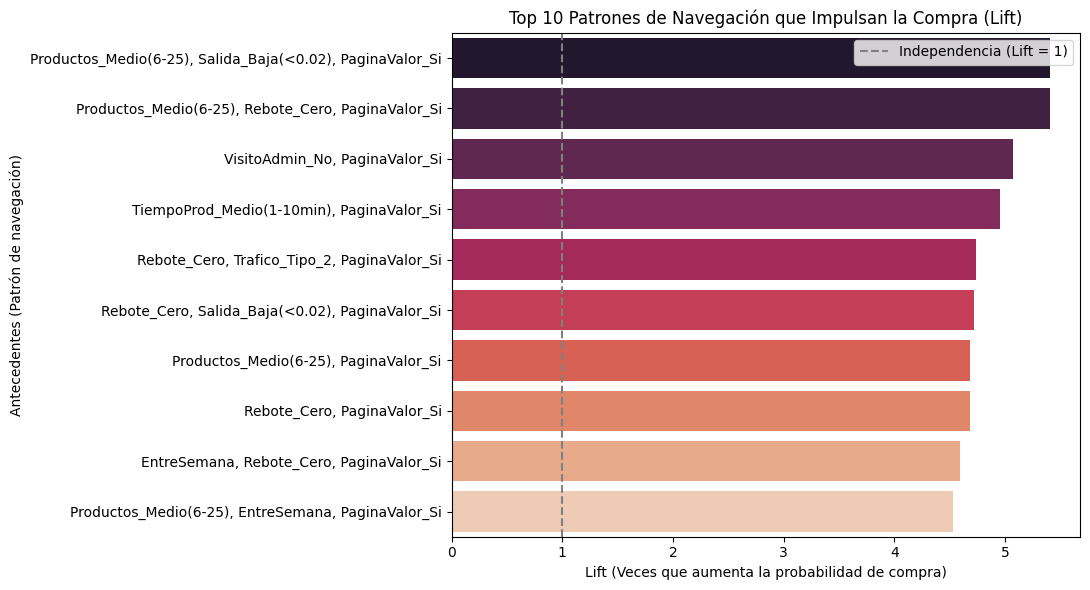

In [ ]:
top10_compra = reglas_compra.head(10).copy()

# Grafica de barras
plt.figure(figsize=(11, 6))
sns.barplot(data=top10_compra, x='lift', y='antecedents_str', palette='rocket')
plt.axvline(1, color='gray', linestyle='--', label='Independencia (Lift = 1)')
plt.title('Top 10 Patrones de Navegación que Impulsan la Compra (Lift)')
plt.xlabel('Lift (Veces que aumenta la probabilidad de compra)')
plt.ylabel('Antecedentes (Patrón de navegación)')
plt.legend()
plt.tight_layout()
plt.show()

##Nota 11:
Se graficó la red dirigida con las 10 reglas principales hacia Compro_True para visualizar qué combinaciones llegan directo a la compra y con qué peso (Lift).

Se ve claro cómo distintos perfiles (Visitante_Recurrente, EntreSemana, Rebote_Cero) terminan apuntando al nodo Compro_True siempre acompañados de PaginaValor_Si.

Mientras que Clustering agrupa sesiones parecidas por distancias y Clasificación predice si un usuario compra o no, Apriori sirve para sacar reglas explícitas (SI pasa X -> ENTONCES pasa Y) basadas en co-ocurrencia dentro de las mismas sesiones.

In [ ]:
tabla_final = top10_compra[['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']].copy()
tabla_final['support (%)'] = (tabla_final['support'] * 100).round(2)
tabla_final['confidence (%)'] = (tabla_final['confidence'] * 100).round(2)
tabla_final['lift'] = tabla_final['lift'].round(2)
display(tabla_final[['antecedents_str', 'consequents_str', 'support (%)', 'confidence (%)', 'lift']])

,antecedents_str,consequents_str,support (%),confidence (%),lift
4009,"Productos_Medio(6-25), Salida_Baja(<0.02), PaginaValor_Si",Compro_True,3.13,84.51,5.41
3998,"Productos_Medio(6-25), Rebote_Cero, PaginaValor_Si",Compro_True,3.92,84.45,5.40
369,"VisitoAdmin_No, PaginaValor_Si",Compro_True,3.18,79.35,5.08
381,"TiempoProd_Medio(1-10min), PaginaValor_Si",Compro_True,3.06,77.43,4.95
4180,"Rebote_Cero, Trafico_Tipo_2, PaginaValor_Si",Compro_True,3.34,74.05,4.74
4151,"Rebote_Cero, Salida_Baja(<0.02), PaginaValor_Si",Compro_True,5.60,73.71,4.71
372,"Productos_Medio(6-25), PaginaValor_Si",Compro_True,5.15,73.22,4.68
388,"Rebote_Cero, PaginaValor_Si",Compro_True,7.14,73.15,4.68
4170,"EntreSemana, Rebote_Cero, PaginaValor_Si",Compro_True,5.22,71.73,4.59
4023,"Productos_Medio(6-25), EntreSemana, PaginaValor_Si",Compro_True,3.74,70.85,4.53


##Nota 12:
El factor decisivo para que exista asociación con la compra es PaginaValor_Si; por el contrario, PaginaValor_Cero aparece en el 74.86% de las sesiones sin compra.

Comprobamos por qué no basta ver la confianza: varias reglas hacia NoCompro_False tienen 100% de confianza pero un Lift de ~1.18 (puro efecto del desbalanceo porque el 84.37% de la tienda no compra), mientras que las reglas de Compro_True alcanzan Lift de 4.73 a 5.46.

##Dispersión Soporte vs Lift

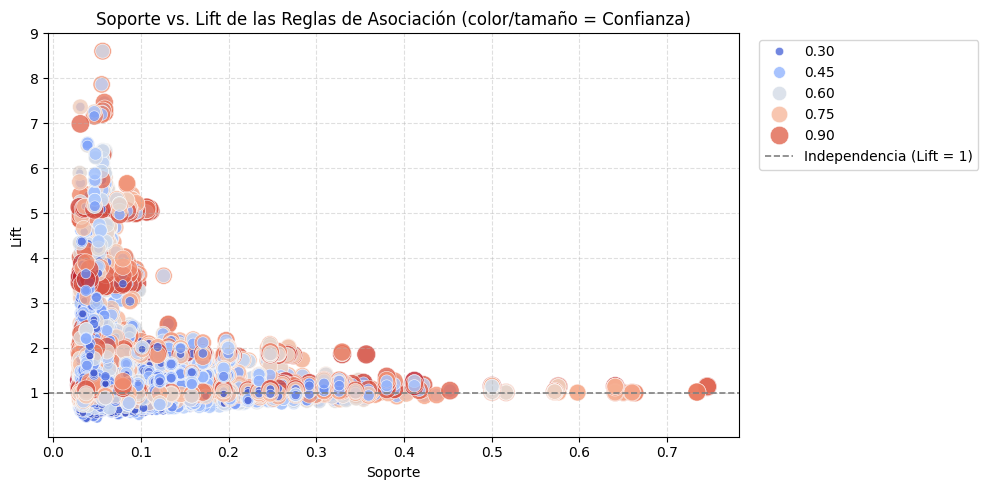

In [ ]:
plt.figure(figsize=(10, 5))
sns.scatterplot(
    data=rules_all, x='support', y='lift', hue='confidence',
    palette='coolwarm', size='confidence', sizes=(25, 200), alpha=0.8
)
plt.axhline(1, color='gray', linestyle='--', linewidth=1.2, label='Independencia (Lift = 1)')
plt.title('Soporte vs. Lift de las Reglas de Asociación (color/tamaño = Confianza)')
plt.xlabel('Soporte')
plt.ylabel('Lift')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

##Nota 13:
Agrupa las reglas de no compra (NoCompro_False). Se ven como puntos grandes a la derecha porque tienen soporte alto y confianza cercana al 100%, pero su Lift ronda 1.18, lo que confirma que casi no aportan ventaja frente al azar.

Concentra las 79 reglas de compra (Compro_True). Aunque su soporte es menor (entre 3% y 7%) porque solo el 15.63% de las sesiones compran, despegan muy por encima de la línea de independencia.

##Red de reglas de asociación

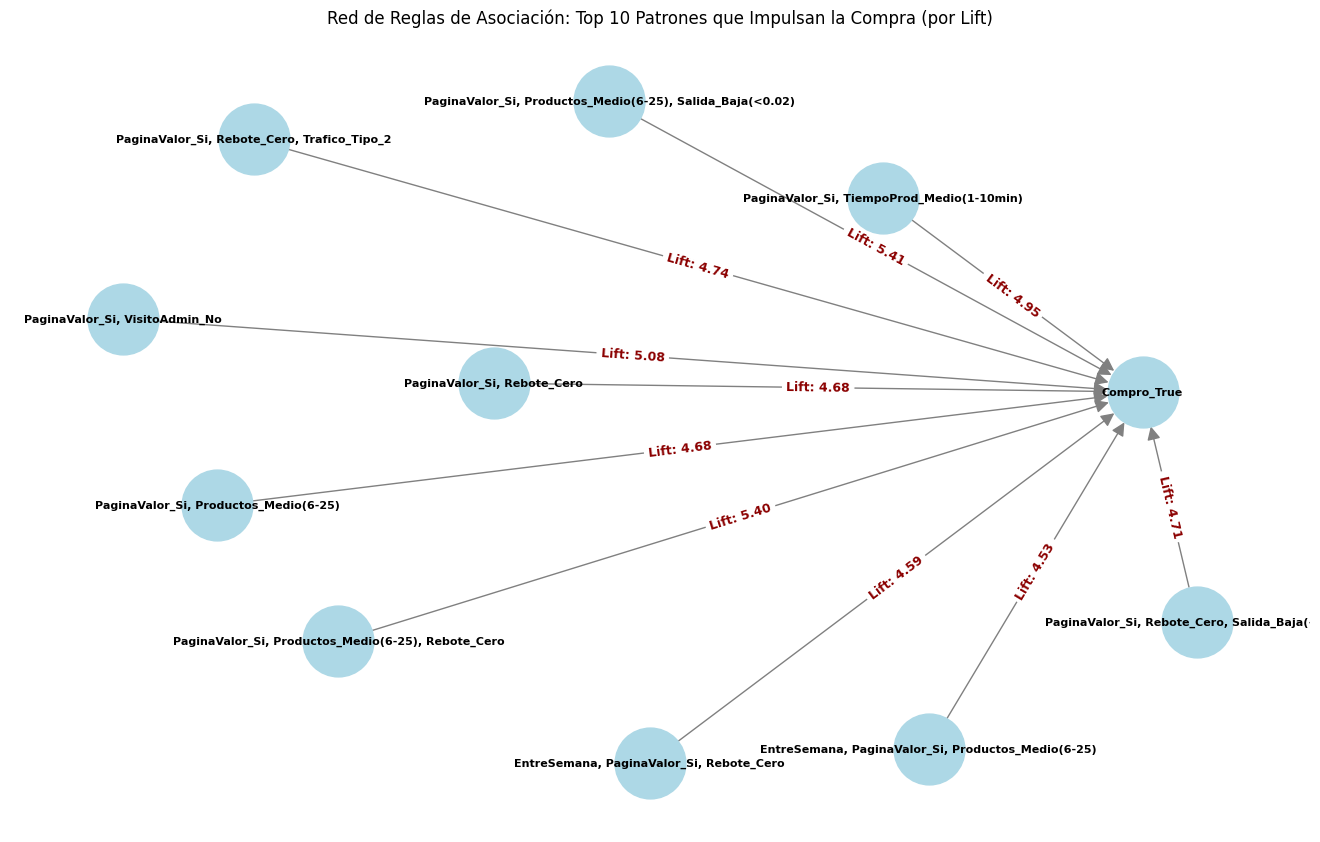

In [ ]:
import networkx as nx

G = nx.DiGraph()
top_rules_red = reglas_compra.head(10)

for _, row in top_rules_red.iterrows():
    antecedente = ', '.join(sorted(row['antecedents']))
    consecuente = ', '.join(sorted(row['consequents']))
    G.add_edge(antecedente, consecuente, weight=row['lift'])

plt.figure(figsize=(13, 8))
pos = nx.spring_layout(G, k=1.4, seed=42)
nx.draw(
    G, pos, with_labels=True, node_size=2600, node_color='lightblue',
    font_size=8, font_weight='bold', arrowsize=20, edge_color='gray'
)
labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(
    G, pos, edge_labels={k: f"Lift: {v:.2f}" for k, v in labels.items()},
    font_color='darkred', font_size=9, font_weight='bold'
)
plt.title('Red de Reglas de Asociación: Top 10 Patrones que Impulsan la Compra (por Lift)')
plt.axis('off')
plt.show()

##Nota 14:
Se construyó una red con las 10 reglas principales hacia Compro_True, representando cada conjunto de condiciones como un nodo completo para no separar combinaciones que solo funcionan juntas.

Todas las flechas apuntan al nodo Compro_True con valores de Lift entre 4.73 y 5.46, dejando claro que distintos caminos (Rebote_Cero, Productos_Medio(6-25), DuracionProd_Largo(>10min)) siempre pasan por PaginaValor_Si como condición clave.

Igual que vimos en clase, estas flechas indican co-ocurrencia dentro de las sesiones históricas y no causalidad directa; a diferencia de Clustering (que agrupa usuarios por similitud) o Clasificación (que predice etiquetas), este grafo entrega reglas explícitas listas para aplicar en la tienda.